# Symbolic Regression using Multi-Objective Genetic Programming


In [1]:
pip install deap

Note: you may need to restart the kernel to use updated packages.


In [2]:
import random
import operator


import numpy as np
import matplotlib.pyplot as plt

from deap import algorithms
from deap import base
from deap import creator
from deap import tools
from deap import gp
from functools import partial

# Fix the random seeds so every run is reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

## Setting up primitives

In [3]:
pset = gp.PrimitiveSet("MAIN", 1)
pset.addPrimitive(np.add, 2)
pset.addPrimitive(np.subtract, 2)
pset.addPrimitive(np.multiply, 2)
pset.addPrimitive(np.negative, 1)
pset.addPrimitive(np.cos, 1)
pset.addPrimitive(np.sin, 1)
pset.addEphemeralConstant("rand101", partial(random.randint, -1, 1))
pset.renameArguments(ARG0='x')

## Setting up Creator

We need two things to perform Genetic Algorithm, which are the individuals containing genotypes and the fitness criteria.

In [4]:
creator.create("FitnessMin", base.Fitness, weights = (-1.0, -1.0)) # weights = (-1, -1) meaning we want to minimize 2 fitness criteria
creator.create("Individual", gp.PrimitiveTree, fitness = creator.FitnessMin)

## Setting up Toolbox

The toolbox is used to register tools (in the form of variables) that are used for Genetic Programming, for example expression of individual, individuals, population, and compiler.

The function to fit is $f(x) = 5x^4 - 4x^3 + 3x^2 - 2x$

In [5]:
toolbox = base.Toolbox()
toolbox.register("expr", gp.genHalfAndHalf, pset = pset, min_= 1, max_= 5)
toolbox.register("individual", tools.initIterate, creator.Individual, toolbox.expr) # Here expr is used as a parameter to define individual
toolbox.register("population", tools.initRepeat, list, toolbox.individual)
toolbox.register("compile", gp.compile, pset=pset) # Transform individual from privimitive tree to function

# Fitness := Root Mean Square Error (RMSE)

def evalSymbReg(individual, points):
    func = gp.compile(expr = individual, pset = pset)
    sqerrors = (func(points) - 5*points**4 + 4*points**3 - 3*points**2 + 2*points)**2 # an array
    return np.sqrt(sum(sqerrors) / len(points)), len(individual)

toolbox.register("evaluate", evalSymbReg, points = np.linspace(-1, 1, 1000)) # The domain for f is 1000 points equally spreaded on [-1, 1]
# NSGA-II ranks by Pareto dominance over (RMSE, tree size), so tree size is a true second objective
# rather than a tie-breaker. It is also elitist: the extreme points of the first front (including the
# lowest-RMSE tree) get infinite crowding distance, so with (mu + lambda) the best tree is never dropped.
# Duplicates must be removed first: copies of one tree share a crowding distance that gets overwritten,
# which lets the best tree fall out and lets the population collapse onto copies of a 1-node tree.
def selNSGA2Unique(individuals, k):
    unique = list({str(ind): ind for ind in individuals}.values())
    return tools.selNSGA2(unique, min(k, len(unique)))

toolbox.register("select", selNSGA2Unique)
toolbox.register("mate", gp.cxOnePoint)
toolbox.register("expr_mut", gp.genFull, min_ = 0, max_ = 2)
toolbox.register("mutate", gp.mutUniform, expr = toolbox.expr_mut, pset = pset)

# Set limits
toolbox.decorate("mate", gp.staticLimit(key=operator.attrgetter("height"), max_value = 17))
toolbox.decorate("mutate", gp.staticLimit(key=operator.attrgetter("height"), max_value = 17))

## Genetic Algorithm

In [6]:
# Initialize population and each individual's fitness values
pop = toolbox.population(n = 300)
fitnesses = list(map(toolbox.evaluate, pop))
for ind, fitness in zip(pop, fitnesses):
    ind.fitness.values = fitness

a_given_individual = toolbox.population(n = 1)[0]
a_given_individual.fitness.values = toolbox.evaluate(a_given_individual)

In [7]:
NGEN = 500
MU = 500
LAMBDA = 1000
CXPB = 0.5
MUTPB = 0.2

random.seed(SEED) # re-seed so this cell gives the same run even when re-executed on its own
pop = toolbox.population(n = MU)
hof = tools.ParetoFront() # store the individuals that are on the pareto front
stats = tools.Statistics(lambda ind: ind.fitness.values)
stats.register("avg", np.mean, axis = 0)
stats.register("std", np.std, axis = 0)
stats.register("min", np.min, axis = 0)
stats.register("max", np.max, axis = 0)

pop, logbook = algorithms.eaMuPlusLambda(pop, toolbox, MU, LAMBDA, CXPB, MUTPB, NGEN, stats,
                          halloffame=hof)

gen	nevals	avg                    	std                    	min                    	max                      
0  	500   	[3.99897359 7.806     ]	[0.45553647 6.51861672]	[2.88956468 2.        ]	[ 6.52762595 46.        ]


1  	704   	[3.77075456 7.808     ]	[0.32557967 5.31818917]	[2.86464843 1.        ]	[ 5.27172521 32.        ]


2  	717   	[3.60426107 8.31      ]	[0.31162748 5.93884669]	[2.72001718 1.        ]	[ 5.27172521 35.        ]


3  	683   	[3.53323769 8.024     ]	[0.35436245 6.08238637]	[2.37381935 1.        ]	[ 5.27172521 38.        ]


4  	683   	[3.44207141 8.338     ]	[0.39894464 6.3125079 ]	[2.12022083 1.        ]	[ 5.27172521 36.        ]


5  	732   	[3.32453175 8.674     ]	[0.37880581 6.76311496]	[2.12022083 1.        ]	[ 4.55840645 38.        ]


... (491 outputs left out)

497	714   	[ 1.02862002 13.608     ]	[0.79568429 4.3811341 ]	[0.05320591 1.        ]	[ 3.97077474 22.        ]


498	698   	[ 1.02356006 13.634     ]	[0.79202842 4.37447643]	[0.05320591 1.        ]	[ 3.97077474 22.        ]


499	676   	[ 1.0148844 13.666    ]  	[0.78370751 4.34815409]	[0.05320591 1.        ]	[ 3.97077474 22.        ]


500	704   	[ 1.0148844 13.666    ]  	[0.78370751 4.34815409]	[0.05320591 1.        ]	[ 3.97077474 22.        ]


## 

## Visualization

Best individual is: multiply(add(x, multiply(multiply(x, x), add(x, x))), add(add(add(x, -1), sin(x)), add(-1, sin(sin(x)))))
with fitness (RMSE, tree size): (np.float64(0.053205912521973854), 22.0)
Best RMSE still in final population: 0.053205912521973854


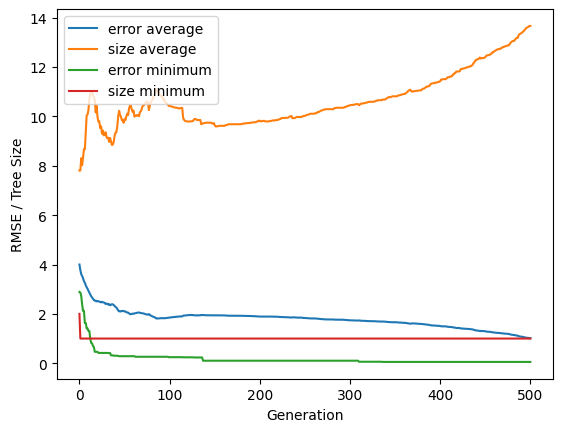

In [8]:
best = min(hof, key = lambda ind: ind.fitness.values[0]) # lowest-RMSE tree on the Pareto front
print("Best individual is: %s\nwith fitness (RMSE, tree size): %s" % (best, best.fitness))
print("Best RMSE still in final population: %s" % min(ind.fitness.values[0] for ind in pop))
gen, avg, min_, max_ = logbook.select("gen", "avg", "min", "max")

error_avg =[a[0] for a in avg]
size_avg = [a[1] for a in avg]
error_min = [a[0] for a in min_]
size_min = [a[1] for a in min_]

plt.plot(gen, error_avg, label="error average")
plt.plot(gen, size_avg, label="size average")

plt.plot(gen, error_min, label="error minimum")
plt.plot(gen, size_min, label="size minimum")

plt.xlabel("Generation")
plt.ylabel("RMSE / Tree Size")
plt.legend(loc="upper left")
plt.show()

## Pareto Front 

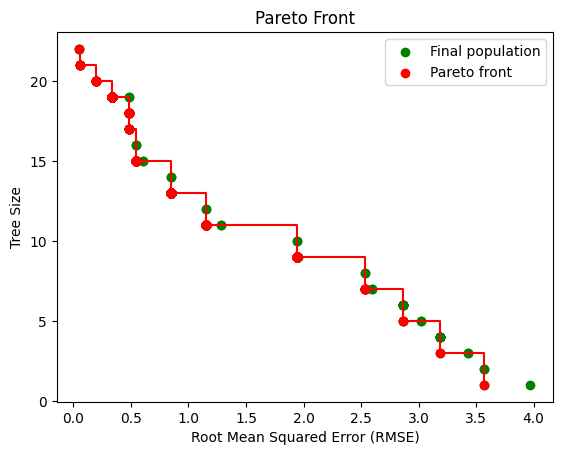

Area Under Curve: 37.242015768727676


In [9]:
# Split fitness values into separate lists
fitness_1 = [ind.fitness.values[0] for ind in hof]
fitness_2 = [ind.fitness.values[1] for ind in hof]
pop_1 = [ind.fitness.values[0] for ind in pop]
pop_2 = [ind.fitness.values[1] for ind in pop]


plt.scatter(pop_1, pop_2, color = 'g', label = 'Final population')
plt.scatter(fitness_1, fitness_2, color = 'r', label = 'Pareto front')
plt.plot(fitness_1, fitness_2, color = 'r', drawstyle = 'steps-post')
plt.xlabel("Root Mean Squared Error (RMSE)")
plt.ylabel("Tree Size")
plt.title("Pareto Front")
plt.legend()
plt.show()

f1 = np.array(fitness_1)
f2 = np.array(fitness_2)

# Calculate area under the Pareto front with a left Riemann sum over the step curve
print("Area Under Curve: %s" % (np.sum(np.abs(np.diff(f1))*f2[:-1])))

In [10]:
print(hof[4], hof[4].fitness)

multiply(add(x, multiply(multiply(x, x), add(x, x))), add(add(sin(x), subtract(add(x, x), 1)), -1)) (np.float64(0.19407675021754792), 20.0)
